# 06 — Shared CatBoost with generator features

**Group 119 — Henrik Remmen (541747)**  
**Kaggle team:** `[119] SINTEF Databreach`

One CatBoost model is shared across all 14 generators. Generator, plant, penstock, capacity, operating range, and cost features tell the model which unit it is predicting.

This directly tests whether pooling data improves cross-generator ranking and probability calibration for the micro ROC-AUC metric.

> Saved unexecuted. This is the most memory-intensive experiment. Start with the default 35% training-row sample.


## 1. Setup and data

In [1]:
from pathlib import Path
import gc
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.sintef_pipeline import (
    HORIZON,
    RANDOM_SEED,
    build_project_data,
    make_submission,
    micro_auc,
    rows_for_cases,
)

try:
    from catboost import CatBoostClassifier
except ImportError as error:
    raise ImportError(
        "Install project dependencies with: pip install -r requirements.txt"
    ) from error

sns.set_theme(style="whitegrid", context="notebook")
FEATURE_SET = "full_engineered"
TRAIN_ROW_FRACTION = 0.35
N_JOBS = 4

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


In [2]:
# DATA/FEATURE CELL — does not train a model
data = build_project_data(ROOT)
FEATURES = data.feature_sets[FEATURE_SET]

# Keep all selected dynamic features. Sampling controls memory, not feature quality.
STATIC_NUMERIC = [
    "generator_number", "p_min", "p_max", "p_nom",
    "minimum_output_fraction", "start_cost", "stop_cost",
    "units_in_plant",
]
CATEGORICAL = ["unit", "plant", "penstock"]
GENERATOR_INFO = data.generator_features.set_index("unit").loc[data.units]

print("Feature set:", FEATURE_SET)
print("Dynamic features:", len(FEATURES))
print("Training-row fraction per generator:", TRAIN_ROW_FRACTION)
display(data.generator_features)


Feature set: full_engineered
Dynamic features: 175
Training-row fraction per generator: 0.35


,unit,plant,generator_number,p_min,p_max,p_nom,minimum_output_fraction,start_cost,stop_cost,penstock,units_in_plant
0,Hogga_G1,Hogga,1,3.0,17.0,17.0,0.176471,94,94,1,1
1,Tokke_G1,Tokke,1,36.9,107.5,107.5,0.343256,214,214,1,4
2,Tokke_G2,Tokke,2,36.9,107.5,107.5,0.343256,214,214,1,4
3,Tokke_G3,Tokke,3,36.9,107.5,107.5,0.343256,214,214,2,4
4,Tokke_G4,Tokke,4,36.9,107.5,107.5,0.343256,214,214,2,4
5,Lio_G1,Lio,1,14.8,43.0,43.0,0.344186,163,163,1,1
6,Byrte_G1,Byrte,1,6.9,20.0,20.0,0.345000,135,135,1,1
7,Vinje_G1,Vinje,1,34.4,100.0,100.0,0.344000,198,198,1,3
8,Vinje_G2,Vinje,2,34.4,100.0,100.0,0.344000,198,198,2,3
9,Vinje_G3,Vinje,3,34.4,100.0,100.0,0.344000,198,198,3,3


## 2. Construct pooled long-format data

Sampling is performed independently for each generator and only on training rows. Validation and test predictions always cover every hour.

In [3]:
def add_generator_columns(frame, unit):
    info = GENERATOR_INFO.loc[unit]
    result = frame.copy()
    for column in STATIC_NUMERIC:
        result[column] = np.float32(info[column])
    for column in CATEGORICAL:
        result[column] = unit if column == "unit" else str(info[column])
    return result

def pooled_training_data(case_ids, fraction, seed):
    rows = rows_for_cases(case_ids)
    dynamic = data.X_all.loc[rows, FEATURES].reset_index(drop=True)
    rng = np.random.default_rng(seed)
    blocks = []
    labels = []

    for unit_index, unit in enumerate(data.units):
        y_unit = data.target_cube[case_ids, unit_index, :].reshape(-1)
        if fraction < 1:
            sample_size = max(1, int(len(dynamic) * fraction))
            selected = np.sort(
                rng.choice(len(dynamic), size=sample_size, replace=False)
            )
        else:
            selected = np.arange(len(dynamic))

        blocks.append(
            add_generator_columns(
                dynamic.iloc[selected].reset_index(drop=True),
                unit,
            )
        )
        labels.append(y_unit[selected])

    X_long = pd.concat(blocks, ignore_index=True)
    y_long = np.concatenate(labels).astype(np.int8)
    return X_long, y_long

def unit_prediction_frame(case_ids, unit):
    rows = rows_for_cases(case_ids)
    dynamic = data.X_all.loc[rows, FEATURES].reset_index(drop=True)
    return add_generator_columns(dynamic, unit)

CATBOOST_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "iterations": 1400,
    "learning_rate": 0.04,
    "depth": 8,
    "l2_leaf_reg": 8.0,
    "random_strength": 0.5,
    "subsample": 0.8,
    "bootstrap_type": "Bernoulli",
    "random_seed": RANDOM_SEED,
    "thread_count": N_JOBS,
    "allow_writing_files": False,
    "verbose": False,
}

def make_shared_catboost(iterations=None):
    params = dict(CATBOOST_PARAMS)
    if iterations is not None:
        params["iterations"] = int(iterations)
    return CatBoostClassifier(**params)


## 3. Purged OOF evaluation

For early stopping, the validation pool is also long-format and complete. If memory is tight, reduce `TRAIN_ROW_FRACTION` to 0.20 before running.

In [4]:
def pooled_validation_data(case_ids):
    blocks = []
    labels = []
    for unit_index, unit in enumerate(data.units):
        blocks.append(unit_prediction_frame(case_ids, unit))
        labels.append(
            data.target_cube[case_ids, unit_index, :].reshape(-1)
        )
    return (
        pd.concat(blocks, ignore_index=True),
        np.concatenate(labels).astype(np.int8),
    )

def evaluate_shared_catboost():
    oof = np.full(data.target_cube.shape, np.nan, dtype=np.float32)
    fold_rows = []
    best_iterations = []

    for fold in data.folds:
        started = time.perf_counter()
        train_case_ids = fold["train_cases"]
        val_case_ids = fold["validation_cases"]

        X_train, y_train = pooled_training_data(
            train_case_ids,
            fraction=TRAIN_ROW_FRACTION,
            seed=RANDOM_SEED + fold["year"],
        )
        X_val_long, y_val_long = pooled_validation_data(val_case_ids)

        print(
            f"{fold['year']}: train rows={len(X_train):,}, "
            f"validation rows={len(X_val_long):,}"
        )
        model = make_shared_catboost()
        model.fit(
            X_train,
            y_train,
            cat_features=CATEGORICAL,
            eval_set=(X_val_long, y_val_long),
            early_stopping_rounds=100,
            verbose=False,
        )
        best_iterations.append(model.get_best_iteration() + 1)

        fold_prediction = np.empty(
            (len(val_case_ids), len(data.units), HORIZON),
            dtype=np.float32,
        )
        for unit_index, unit in enumerate(data.units):
            X_unit = unit_prediction_frame(val_case_ids, unit)
            prediction = model.predict_proba(X_unit)[:, 1]
            fold_prediction[:, unit_index, :] = prediction.reshape(
                len(val_case_ids), HORIZON
            )

        oof[val_case_ids] = fold_prediction
        score = micro_auc(data.target_cube[val_case_ids], fold_prediction)
        elapsed = time.perf_counter() - started
        fold_rows.append({
            "validation_year": fold["year"],
            "micro_auc": score,
            "best_iteration": best_iterations[-1],
            "seconds": elapsed,
        })
        print(
            f"Shared CatBoost | {fold['year']} | "
            f"micro AUC={score:.6f} | {elapsed:.1f}s"
        )

        del X_train, y_train, X_val_long, y_val_long, model
        gc.collect()

    return {
        "oof": oof,
        "fold_scores": pd.DataFrame(fold_rows),
        "best_iterations": best_iterations,
    }


In [5]:
# TRAINING CELL A — shared-model chronological OOF
shared_result = evaluate_shared_catboost()
shared_fold_scores = shared_result["fold_scores"]

display(shared_fold_scores.style.format({
    "micro_auc": "{:.6f}",
    "seconds": "{:.1f}",
}))
print("Mean AUC:", shared_fold_scores["micro_auc"].mean())
print("Worst-fold AUC:", shared_fold_scores["micro_auc"].min())

artifact_dir = ROOT / "artifacts" / "predictions"
artifact_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    artifact_dir / "catboost_shared_oof.npz",
    oof=shared_result["oof"],
)
shared_fold_scores.to_csv(
    artifact_dir / "catboost_shared_fold_scores.csv",
    index=False,
)


2020: train rows=1,498,224, validation rows=860,832
Shared CatBoost | 2020 | micro AUC=0.911002 | 447.7s
2021: train rows=1,799,504, validation rows=858,480
Shared CatBoost | 2021 | micro AUC=0.969907 | 1106.6s
2022: train rows=2,099,972, validation rows=858,480
Shared CatBoost | 2022 | micro AUC=0.978252 | 1562.9s


,validation_year,micro_auc,best_iteration,seconds
0,2020,0.911002,488,447.7
1,2021,0.969907,1142,1106.6
2,2022,0.978252,1400,1562.9


Mean AUC: 0.9530540774627022
Worst-fold AUC: 0.9110024352085928


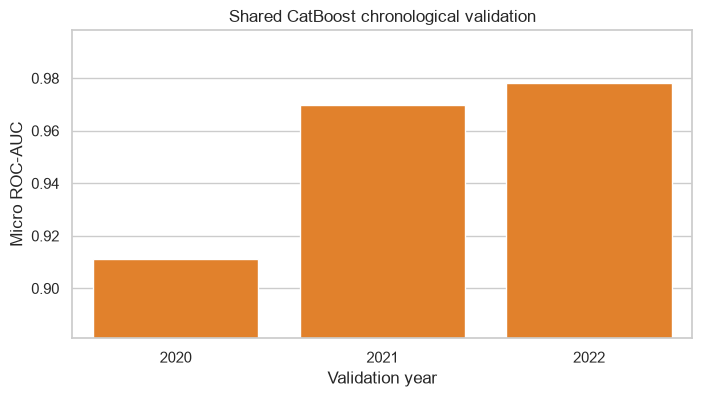

In [6]:
# FAST ANALYSIS CELL — no training
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=shared_fold_scores,
    x="validation_year",
    y="micro_auc",
    color="tab:orange",
    ax=ax,
)
ax.set(
    title="Shared CatBoost chronological validation",
    xlabel="Validation year",
    ylabel="Micro ROC-AUC",
)
ax.set_ylim(
    max(0.5, shared_fold_scores["micro_auc"].min() - 0.03),
    min(1.0, shared_fold_scores["micro_auc"].max() + 0.02),
)
plt.show()


## 4. Full training and submission

In [7]:
# TRAINING CELL B — one final shared CatBoost model
all_train_cases = np.arange(data.n_train_cases)
X_train_long, y_train_long = pooled_training_data(
    all_train_cases,
    fraction=TRAIN_ROW_FRACTION,
    seed=RANDOM_SEED,
)
final_iterations = max(
    100,
    int(np.median(shared_result["best_iterations"])),
)
shared_model = make_shared_catboost(iterations=final_iterations)
shared_model.fit(
    X_train_long,
    y_train_long,
    cat_features=CATEGORICAL,
    verbose=False,
)
print("Final iterations:", final_iterations)

test_case_ids = np.arange(data.n_train_cases, data.n_all_cases)
test_prediction = np.empty(
    (data.n_test_cases, len(data.units), HORIZON),
    dtype=np.float32,
)
for unit_index, unit in enumerate(data.units):
    X_unit_test = unit_prediction_frame(test_case_ids, unit)
    prediction = shared_model.predict_proba(X_unit_test)[:, 1]
    test_prediction[:, unit_index, :] = prediction.reshape(
        data.n_test_cases, HORIZON
    )
    print("Predicted:", unit)

submission_path, submission = make_submission(
    data,
    test_prediction,
    "catboost_shared.csv",
)
print("Saved:", submission_path)
display(submission.iloc[:3, :8])


Final iterations: 1142
Predicted: Hogga_G1
Predicted: Tokke_G1
Predicted: Tokke_G2
Predicted: Tokke_G3
Predicted: Tokke_G4
Predicted: Lio_G1
Predicted: Byrte_G1
Predicted: Vinje_G1
Predicted: Vinje_G2
Predicted: Vinje_G3
Predicted: Haukeli_G1
Predicted: Songa_G1
Predicted: Kjela_G1
Predicted: Vesle Kjela_G1
Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/submissions/catboost_shared.csv


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.160409,0.149964,0.117588,0.090172,0.111217,0.094780,0.055033
1,2924,0.924947,0.898043,0.923311,0.943563,0.916741,0.947602,0.991465
2,2925,0.966452,0.971820,0.971286,0.974098,0.973758,0.991200,0.995641


### Kaggle description

`Shared CatBoost – generator and plant features, 35% pooled training sample`

Do not increase the sample fraction until the 35% version has completed successfully and its OOF score justifies the extra runtime.
